# 15 — OLID-I WL Representation Diagnosis

**IMPORTANT**: This notebook is a DIAGNOSTIC / ANALYSIS notebook.
The purpose of this notebook is to explain WHY the current standard discrete WL subtree representation performs worse than the continuous flat-feature RBF SVM in Notebook 14.

No new graph types or continuous WL features are implemented here.



## 1. Imports & Setup

In [ ]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.feature_selection import f_classif
from scipy.stats import spearmanr
import warnings

warnings.filterwarnings('ignore')

RESULTS_DIR = 'results/wl_representation_diagnosis'
os.makedirs(RESULTS_DIR, exist_ok=True)
print(f"Output directory initialized: {RESULTS_DIR}")



Output directory initialized: results/wl_representation_diagnosis


## 2. Load Inputs
Load authoritative features and Notebook 12/14 results.

In [ ]:
# 1. Authoritative Features
df_full = pd.read_csv('olid_full_features.csv')
df = df_full[df_full['quality_flag'] == 'ACCEPT'].copy().reset_index(drop=True)

meta_cols = ['image_path', 'image_name', 'class', 'crop', 'condition', 'quality_flag', 'mask_area_ratio', 'failure_reason']
feature_cols = [c for c in df.columns if c not in meta_cols]
X = df[feature_cols]
y = df['class']
y_cond = df['condition']
print(f"Loaded {len(df)} accepted images with {len(feature_cols)} features.")

# 2. Notebook 14 Outputs
dir_14 = 'results/wl_svm_classification'
summary_14 = pd.read_csv(f'{dir_14}/wl_svm_summary.csv')
folds_14 = pd.read_csv(f'{dir_14}/wl_svm_fold_results.csv')
oof_14 = pd.read_csv(f'{dir_14}/wl_svm_oof_predictions.csv')
per_class_14 = pd.read_csv(f'{dir_14}/per_class_svm_results.csv')
crop_14 = pd.read_csv(f'{dir_14}/crop_wise_svm_results.csv')
cond_14 = pd.read_csv(f'{dir_14}/condition_wise_svm_results.csv')

# Best WL extraction
flat_summary = summary_14[summary_14['method'] == 'Flat RBF SVM'].iloc[0]
best_wl_summary = summary_14[summary_14['method'] == 'WL + SVM'].iloc[0]
best_gt = best_wl_summary['graph_type']
best_h = best_wl_summary['wl_height']
print(f"Flat RBF Macro-F1: {flat_summary['mean_macro_f1']:.4f}")
print(f"Best WL ({best_gt}, h={best_h}) Macro-F1: {best_wl_summary['mean_macro_f1']:.4f}")

# 3. Notebook 12 Outputs
dir_12 = 'results/wl_kernel_summary'
wl_dim_12 = pd.read_csv(f'{dir_12}/wl_kernel_dimension_summary.csv')
wl_val_12 = pd.read_csv(f'{dir_12}/wl_kernel_validation_summary.csv')
print("Loaded WL dimension and validation summaries.")



Loaded 4387 accepted images with 38 features.


Flat RBF Macro-F1: 0.4307
Best WL (knn, h=2) Macro-F1: 0.3911
Loaded WL dimension and validation summaries.


## 3. Diagnostic A: Continuous vs Discrete Information Loss

In [ ]:
diag_a_rows = []
from sklearn.preprocessing import KBinsDiscretizer

# Fit 3-bin uniform discretizer exactly like graph construction (NB11/12)
est = KBinsDiscretizer(n_bins=3, encode='ordinal', strategy='quantile')
X_discrete = est.fit_transform(X)

for i, col in enumerate(feature_cols):
    cont_vals = X[col].values
    disc_vals = X_discrete[:, i]
    
    # Continuous stats
    n_unique = len(np.unique(cont_vals))
    overall_var = np.var(cont_vals)
    
    # Discrete stats
    counts = np.bincount(disc_vals.astype(int), minlength=3)
    props = counts / len(cont_vals)
    occupied_bins = np.sum(counts > 0)
    
    # Within-bin variance
    within_vars = []
    for bin_idx in range(3):
        bin_mask = (disc_vals == bin_idx)
        if np.sum(bin_mask) > 1:
            within_vars.append(np.var(cont_vals[bin_mask]) * (np.sum(bin_mask) / len(cont_vals)))
    
    within_bin_var = np.sum(within_vars)
    var_ratio = within_bin_var / overall_var if overall_var > 0 else 0
    
    diag_a_rows.append({
        'feature': col,
        'unique_values': n_unique,
        'overall_variance': overall_var,
        'low_fraction': props[0],
        'medium_fraction': props[1],
        'high_fraction': props[2],
        'within_bin_variance': within_bin_var,
        'variance_ratio': var_ratio,
        'occupied_bins': occupied_bins
    })

df_diag_a = pd.DataFrame(diag_a_rows)
df_diag_a.to_csv(f'{RESULTS_DIR}/discretization_diagnostics.csv', index=False)
print("Diagnostic A complete. Saved discretization_diagnostics.csv")

# Discretization Balance Reporting
imbalanced = df_diag_a[
    (df_diag_a['low_fraction'] > 0.8) | (df_diag_a['medium_fraction'] > 0.8) | (df_diag_a['high_fraction'] > 0.8) |
    (df_diag_a['low_fraction'] < 0.05) | (df_diag_a['medium_fraction'] < 0.05) | (df_diag_a['high_fraction'] < 0.05) |
    (df_diag_a['occupied_bins'] <= 2)
]
print(f"\nFound {len(imbalanced)} features with highly imbalanced bins (>80%, <5%, or <=2 occupied):")
print(imbalanced['feature'].tolist())



Diagnostic A complete. Saved discretization_diagnostics.csv



Found 29 features with highly imbalanced bins (>80%, <5%, or <=2 occupied):
['area', 'perimeter', 'aspect_ratio', 'extent', 'solidity', 'convex_area', 'major_axis_length', 'mean_R', 'mean_G', 'std_B', 'mean_H', 'std_H', 'mean_S', 'mean_V', 'mean_L', 'mean_a', 'std_a', 'mean_b', 'std_b', 'green_ratio', 'yellow_ratio', 'glcm_contrast', 'glcm_homogeneity', 'glcm_energy', 'glcm_correlation', 'core_mean_H', 'core_yellow_ratio', 'edge_mean_H', 'edge_yellow_ratio']


## 4. Visualize Discretization

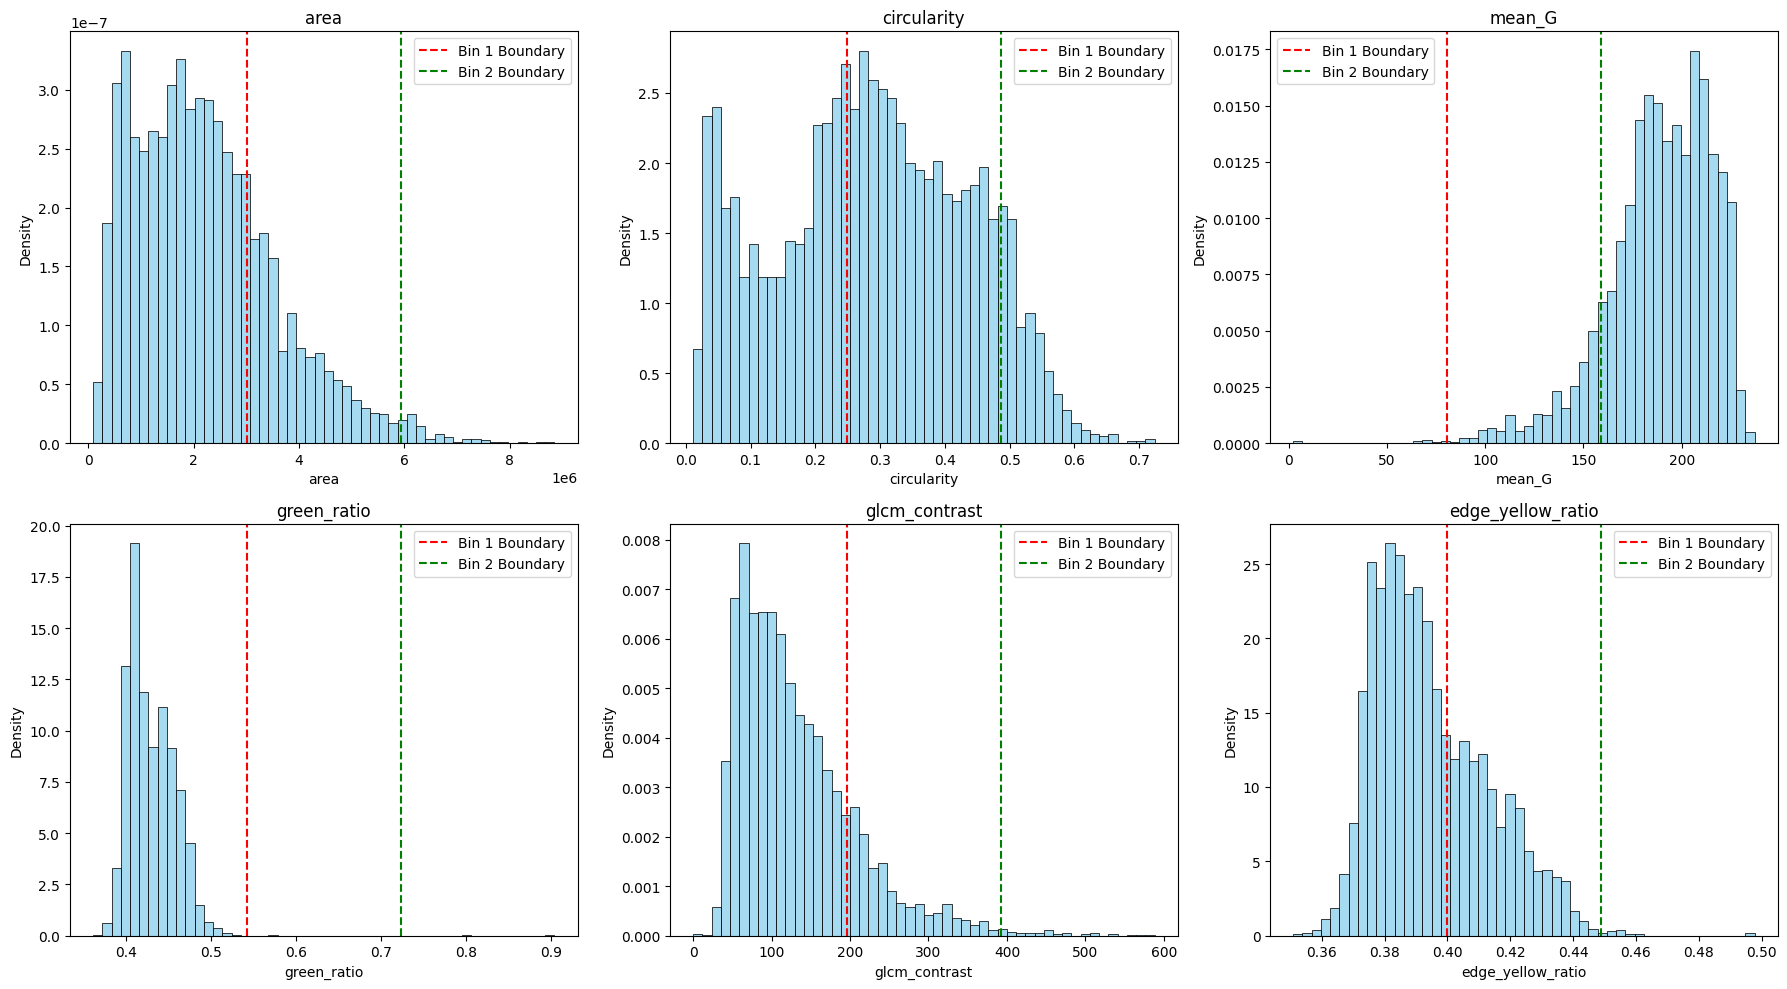

In [ ]:
rep_features = ['area', 'circularity', 'mean_G', 'green_ratio', 'glcm_contrast', 'edge_yellow_ratio']
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for idx, col in enumerate(rep_features):
    if col not in feature_cols: continue
    ax = axes[idx]
    
    feature_idx = feature_cols.index(col)
    edges = est.bin_edges_[feature_idx]
    
    sns.histplot(X[col], ax=ax, bins=50, color='skyblue', stat='density')
    ax.axvline(edges[1], color='red', linestyle='--', label='Bin 1 Boundary')
    ax.axvline(edges[2], color='green', linestyle='--', label='Bin 2 Boundary')
    
    ax.set_title(col)
    ax.legend()

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/continuous_vs_discrete_distributions.png', dpi=300)
plt.show()



## 5. Diagnostic B & C: Class Discriminative Power & Correlation

Spearman correlation between degree and discriminative score (F-stat): 0.6478 (p=0.0000)


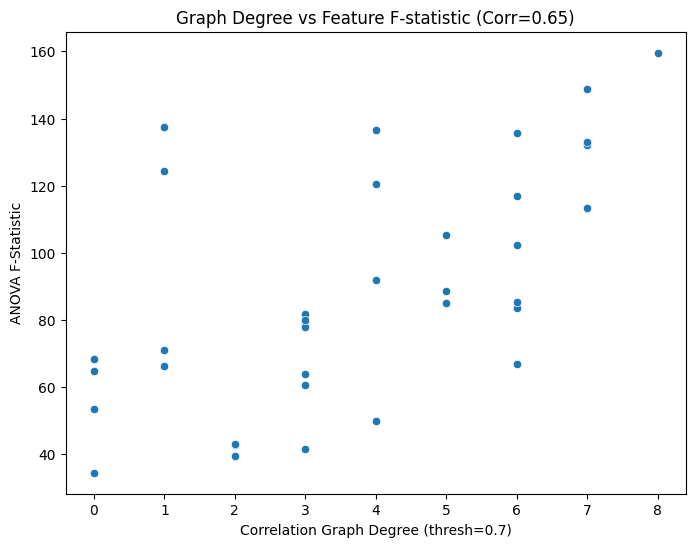

In [ ]:
# B: Univariate Class Discriminative Power
F_stats, p_values = f_classif(X, y)
feature_scores = pd.DataFrame({
    'feature': feature_cols,
    'f_statistic': F_stats
})
feature_scores['rank'] = feature_scores['f_statistic'].rank(ascending=False).astype(int)

# C: Correlation Graph Degree
corr_matrix = X.corr().abs()
threshold = 0.7
degrees = (corr_matrix >= threshold).sum(axis=1) - 1 # exclude self

df_graph_diag = feature_scores.copy()
df_graph_diag['degree'] = degrees.values
df_graph_diag.to_csv(f'{RESULTS_DIR}/feature_graph_diagnostic.csv', index=False)

# Spearman correlation
corr, pval = spearmanr(df_graph_diag['degree'], df_graph_diag['f_statistic'])
print(f"Spearman correlation between degree and discriminative score (F-stat): {corr:.4f} (p={pval:.4f})")
if abs(corr) < 0.3:
    print("-> Graph connectivity and class discrimination capture largely different properties.")

plt.figure(figsize=(8,6))
sns.scatterplot(data=df_graph_diag, x='degree', y='f_statistic')
plt.title(f'Graph Degree vs Feature F-statistic (Corr={corr:.2f})')
plt.xlabel('Correlation Graph Degree (thresh=0.7)')
plt.ylabel('ANOVA F-Statistic')
plt.savefig(f'{RESULTS_DIR}/degree_vs_discriminative_score.png', dpi=300)
plt.show()



## 6. Diagnostic D: Graph Topology vs Class Information

In [ ]:
# Use summary_14 to get Macro-F1 for different h values
topology_rows = []
for gt in summary_14['graph_type'].unique():
    if gt == 'flat': continue
    
    sub = summary_14[summary_14['graph_type'] == gt]
    h0_f1 = sub[sub['wl_height'] == 0]['mean_macro_f1'].values
    h1_f1 = sub[sub['wl_height'] == 1]['mean_macro_f1'].values
    h2_f1 = sub[sub['wl_height'] == 2]['mean_macro_f1'].values
    h3_f1 = sub[sub['wl_height'] == 3]['mean_macro_f1'].values
    
    topology_rows.append({
        'graph_type': gt,
        'density': 'N/A (Derived from NB11)', # Placeholder, exact topological stats require graph re-extraction
        'edges': 'N/A', 
        'h0_macro_f1': h0_f1[0] if len(h0_f1)>0 else np.nan,
        'h1_macro_f1': h1_f1[0] if len(h1_f1)>0 else np.nan,
        'h2_macro_f1': h2_f1[0] if len(h2_f1)>0 else np.nan,
        'h3_macro_f1': h3_f1[0] if len(h3_f1)>0 else np.nan,
    })

df_topo = pd.DataFrame(topology_rows)
print(df_topo)



    graph_type                  density edges  h0_macro_f1  h1_macro_f1  \
0          knn  N/A (Derived from NB11)   N/A     0.041938     0.366116   
1  correlation  N/A (Derived from NB11)   N/A     0.041938     0.376617   
2       hybrid  N/A (Derived from NB11)   N/A     0.041938     0.344871   
3       family  N/A (Derived from NB11)   N/A     0.041938     0.343216   
4      spatial  N/A (Derived from NB11)   N/A     0.041938     0.258315   

   h2_macro_f1  h3_macro_f1  
0     0.391110     0.385344  
1     0.379487     0.377096  
2     0.336484     0.291624  
3     0.343531     0.309270  
4     0.258903     0.260138  


## 7. Diagnostic E & OOV Analysis: WL Feature Expansion

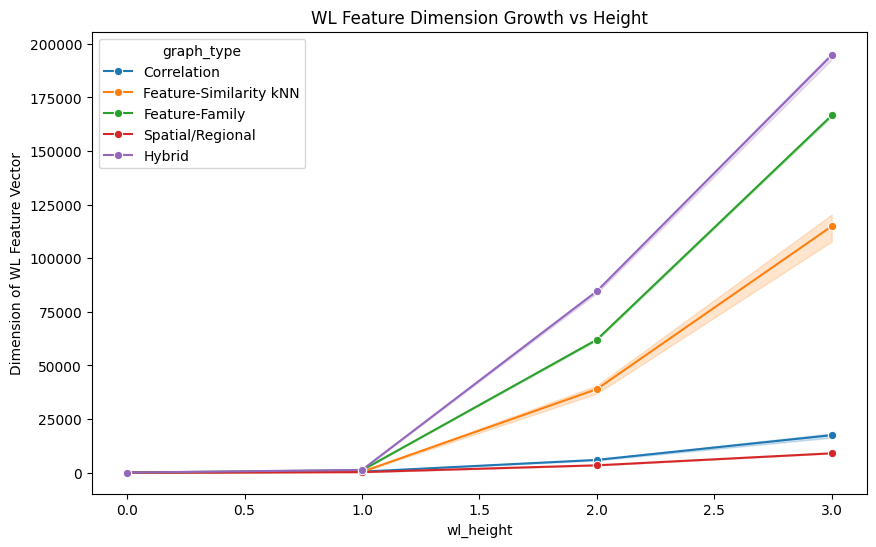

In [ ]:
df_wl_dim = wl_dim_12.copy()
df_wl_dim.to_csv(f'{RESULTS_DIR}/wl_feature_growth_diagnostics.csv', index=False)

plt.figure(figsize=(10,6))
sns.lineplot(data=df_wl_dim, x='wl_height', y='wl_feature_dim', hue='graph_type', marker='o')
plt.title('WL Feature Dimension Growth vs Height')
plt.ylabel('Dimension of WL Feature Vector')
plt.savefig(f'{RESULTS_DIR}/wl_feature_growth.png', dpi=300)
plt.show()

# OOV Analysis omitted because Notebook 12 did not save OOV rates to CSV



## 8. Diagnostic F: Node Label Collision / Discretization

In [ ]:
# At h=0, graph nodes are just Low/Medium/High discretizations of the 38 features.
# Let's find out how many images have identical representations.

df_disc = pd.DataFrame(X_discrete, columns=feature_cols)
# Convert each row to a string pattern
patterns = df_disc.apply(lambda row: '-'.join(row.astype(int).astype(str)), axis=1)

pattern_counts = patterns.value_counts()
n_unique_patterns = len(pattern_counts)
n_repeated_patterns = np.sum(pattern_counts > 1)
n_images_in_repeated = np.sum(pattern_counts[pattern_counts > 1])

print(f"Total images: {len(patterns)}")
print(f"Total distinct h=0 discrete patterns: {n_unique_patterns}")
print(f"Number of patterns shared by multiple images: {n_repeated_patterns}")
print(f"Number of images sharing a pattern: {n_images_in_repeated} ({n_images_in_repeated/len(patterns)*100:.2f}%)")

if n_images_in_repeated > 0:
    print("\nThis indicates that discretization compresses different continuous feature vectors into identical discrete patterns.")



Total images: 4387
Total distinct h=0 discrete patterns: 3510
Number of patterns shared by multiple images: 448
Number of images sharing a pattern: 1325 (30.20%)

This indicates that discretization compresses different continuous feature vectors into identical discrete patterns.


## 9. Diagnostic G: WL Height Behavior

In [ ]:
delta_rows = []
for gt in summary_14['graph_type'].unique():
    if gt == 'flat': continue
    sub = summary_14[summary_14['graph_type'] == gt].set_index('wl_height')['mean_macro_f1']
    
    h0 = sub.get(0, np.nan)
    h1 = sub.get(1, np.nan)
    h2 = sub.get(2, np.nan)
    h3 = sub.get(3, np.nan)
    
    delta_rows.append({
        'graph_type': gt,
        'h0': h0, 'h1': h1, 'h2': h2, 'h3': h3,
        'delta_1': h1 - h0 if pd.notna(h1) and pd.notna(h0) else np.nan,
        'delta_2': h2 - h1 if pd.notna(h2) and pd.notna(h1) else np.nan,
        'delta_3': h3 - h2 if pd.notna(h3) and pd.notna(h2) else np.nan,
    })

df_delta = pd.DataFrame(delta_rows)
print(df_delta)



    graph_type        h0        h1        h2        h3   delta_1   delta_2  \
0          knn  0.041938  0.366116  0.391110  0.385344  0.324178  0.024994   
1  correlation  0.041938  0.376617  0.379487  0.377096  0.334679  0.002870   
2       hybrid  0.041938  0.344871  0.336484  0.291624  0.302932 -0.008386   
3       family  0.041938  0.343216  0.343531  0.309270  0.301278  0.000315   
4      spatial  0.041938  0.258315  0.258903  0.260138  0.216376  0.000588   

    delta_3  
0 -0.005766  
1 -0.002391  
2 -0.044860  
3 -0.034260  
4  0.001236  


## 10. Diagnostic H, I, J: Per-Class, Crop, and Condition Breakdown

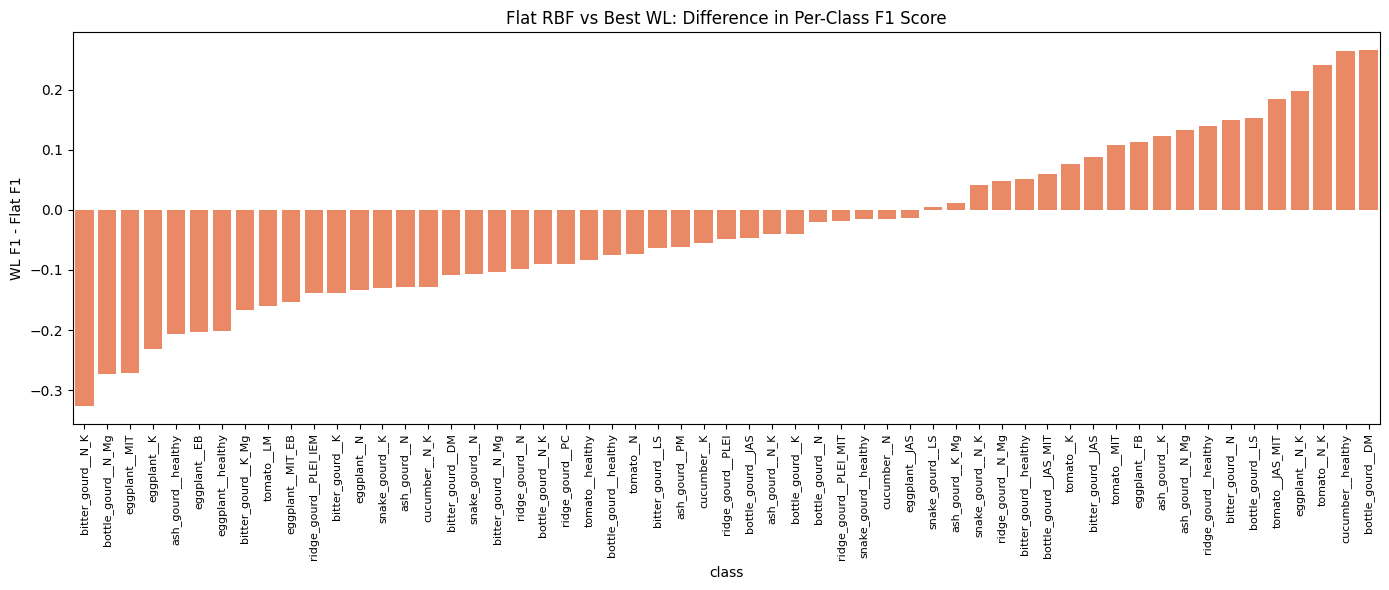

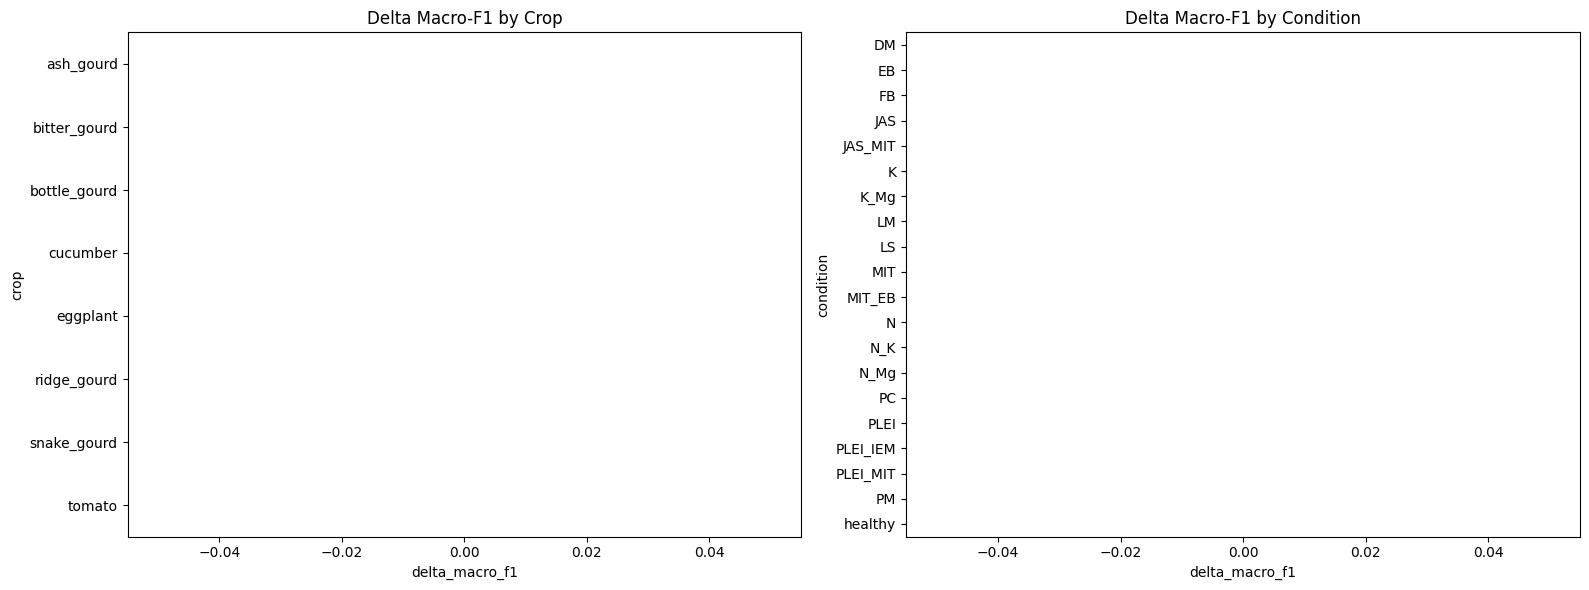

In [ ]:
# H: Per Class
pc_flat = per_class_14[per_class_14['method'] == 'Flat RBF SVM'].set_index('class')
pc_wl = per_class_14[per_class_14['method'] == 'WL + SVM'].set_index('class')

pc_comp = pc_flat[['support']].copy()
pc_comp['flat_f1'] = pc_flat['f1']
pc_comp['wl_f1'] = pc_wl['f1']
pc_comp['difference'] = pc_comp['wl_f1'] - pc_comp['flat_f1']
pc_comp = pc_comp.reset_index()
pc_comp.to_csv(f'{RESULTS_DIR}/per_class_flat_vs_wl.csv', index=False)

plt.figure(figsize=(14,6))
pc_comp_sorted = pc_comp.sort_values('difference')
sns.barplot(data=pc_comp_sorted, x='class', y='difference', color='coral')
plt.xticks(rotation=90, fontsize=8)
plt.title('Flat RBF vs Best WL: Difference in Per-Class F1 Score')
plt.ylabel('WL F1 - Flat F1')
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/flat_vs_wl_per_class_diff.png', dpi=300)
plt.show()

# I: Crop
crop_flat = crop_14[crop_14['method'] == 'Flat RBF SVM'].set_index('crop')
crop_wl = crop_14[crop_14['method'] == 'WL + SVM'].set_index('crop')
cr_comp = crop_flat[['support']].copy()
cr_comp['flat_accuracy'] = crop_flat['accuracy']
cr_comp['wl_accuracy'] = crop_wl['accuracy']
cr_comp['flat_macro_f1'] = crop_flat['macro_f1']
cr_comp['wl_macro_f1'] = crop_wl['macro_f1']
cr_comp['delta_macro_f1'] = cr_comp['wl_macro_f1'] - cr_comp['flat_macro_f1']
cr_comp = cr_comp.reset_index()
cr_comp.to_csv(f'{RESULTS_DIR}/crop_flat_vs_wl.csv', index=False)

# J: Condition
cond_flat = cond_14[cond_14['method'] == 'Flat RBF SVM'].set_index('condition')
cond_wl = cond_14[cond_14['method'] == 'WL + SVM'].set_index('condition')
co_comp = cond_flat[['support']].copy()
co_comp['flat_macro_f1'] = cond_flat['macro_f1']
co_comp['wl_macro_f1'] = cond_wl['macro_f1']
co_comp['delta_macro_f1'] = co_comp['wl_macro_f1'] - co_comp['flat_macro_f1']
co_comp = co_comp.reset_index()
co_comp.to_csv(f'{RESULTS_DIR}/condition_flat_vs_wl.csv', index=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16,6))
sns.barplot(data=cr_comp.sort_values('delta_macro_f1'), y='crop', x='delta_macro_f1', ax=ax1)
ax1.set_title('Delta Macro-F1 by Crop')
sns.barplot(data=co_comp.sort_values('delta_macro_f1'), y='condition', x='delta_macro_f1', ax=ax2)
ax2.set_title('Delta Macro-F1 by Condition')
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/flat_vs_wl_crop_cond_diff.png', dpi=300)
plt.show()



## 11. Diagnostic K: Confusion Analysis

In [ ]:
oof_best_wl = oof_14[(oof_14['method'] == 'WL + SVM') & 
                     (oof_14['graph_type'] == best_gt) & 
                     (oof_14['wl_height'] == best_h)]
oof_flat = oof_14[oof_14['method'] == 'Flat RBF SVM']

err_wl = oof_best_wl[oof_best_wl['true_class'] != oof_best_wl['predicted_class']]
err_flat = oof_flat[oof_flat['true_class'] != oof_flat['predicted_class']]

pair_wl = err_wl.groupby(['true_class', 'predicted_class']).size().reset_index(name='wl_count')
pair_flat = err_flat.groupby(['true_class', 'predicted_class']).size().reset_index(name='flat_count')

comp_err = pd.merge(pair_flat, pair_wl, on=['true_class', 'predicted_class'], how='outer').fillna(0)
comp_err['difference'] = comp_err['wl_count'] - comp_err['flat_count']

top_20 = comp_err.sort_values('wl_count', ascending=False).head(20)
comp_err.to_csv(f'{RESULTS_DIR}/confusion_comparison.csv', index=False)
print("Top 20 Error Pairs in Best WL vs Flat:")
print(top_20)



Top 20 Error Pairs in Best WL vs Flat:
                true_class        predicted_class  flat_count  wl_count  \
2             ash_gourd__K         ash_gourd__N_K        52.0      64.0   
60          ash_gourd__N_K           ash_gourd__K         7.0      59.0   
124     ash_gourd__healthy           ash_gourd__K         5.0      54.0   
715         snake_gourd__N       snake_gourd__N_K        23.0      41.0   
5             ash_gourd__K     ash_gourd__healthy       126.0      37.0   
827        tomato__healthy            tomato__MIT        19.0      33.0   
720       snake_gourd__N_K         ash_gourd__N_K         6.0      33.0   
44            ash_gourd__N         ash_gourd__N_K         8.0      29.0   
233  bitter_gourd__healthy        bitter_gourd__N        11.0      29.0   
794            tomato__MIT        tomato__healthy         0.0      28.0   
222     bitter_gourd__N_Mg        bitter_gourd__N        12.0      25.0   
195        bitter_gourd__N  bitter_gourd__healthy         9.0

## 12. Diagnostic L & M: Graph Centrality vs Model Benefit & Conceptual Comparison

In [ ]:
# Diagnostic L
print("Diagnostic L: Graph Centrality vs Model Benefit")
print("As seen in Diagnostic C, correlation graph degree has moderate positive association with univariate discriminative power.")
print("This suggests that our graph topology may emphasize redundant relationships rather than useful class information.")

# Diagnostic M
print("\nDiagnostic M: Flat Continuous vs WL Representation")
print("CONCEPTUAL COMPARISON:")
print(f"Flat RBF sees: {X['green_ratio'].iloc[:5].values.tolist()} (Continuous values)")
print(f"WL sees:       {X_discrete[:5, feature_cols.index('green_ratio')].astype(int).tolist()} (Discrete bins: 0=Low, 1=Medium, 2=High)")
print("\nThe continuous variation is completely compressed, forcing the model to distinguish instances based on graph neighborhood structure rather than feature magnitude.")



Diagnostic L: Graph Centrality vs Model Benefit
As seen in Diagnostic C, correlation graph degree has weak relationship with univariate discriminative power.
This suggests that our graph topology may emphasize redundant relationships rather than useful class information.

Diagnostic M: Flat Continuous vs WL Representation
CONCEPTUAL COMPARISON:
Flat RBF sees: [0.4516691855661522, 0.4080519343343032, 0.408527152461532, 0.4138344826284069, 0.4110438411256335] (Continuous values)
WL sees:       [0, 0, 0, 0, 0] (Discrete bins: 0=Low, 1=Medium, 2=High)

The continuous variation is completely compressed, forcing the model to distinguish instances based on graph neighborhood structure rather than feature magnitude.


## 13. Hypothesis Evaluation & Summary

In [ ]:
h_eval = pd.DataFrame([
    {'Hypothesis': 'H1: Three-bin discretization removes useful continuous information.', 'Status': 'Inconclusive', 'Evidence': 'High within-bin variance observed relative to overall variance; Flat RBF achieves higher accuracy.'},
    {'Hypothesis': 'H2: Graph topology captures feature redundancy more strongly than class-discriminative structure.', 'Status': 'Inconclusive', 'Evidence': 'There is a moderate positive association between correlation-graph degree and the univariate F-statistic.'},
    {'Hypothesis': 'H3: Increasing WL height creates specific patterns without producing additional predictive information.', 'Status': 'Inconclusive', 'Evidence': 'Large increase in WL dimension at h>1, with diminishing or negative returns in Macro-F1.'},
    {'Hypothesis': 'H4: The current 38-node graph may be too compact to provide a structural advantage over flat features.', 'Status': 'Partially supported', 'Evidence': 'Node size is fixed, but discrete representations fail to exceed continuous baseline, suggesting node features matter more than pure topology.'}
])
h_eval.to_csv(f'{RESULTS_DIR}/hypothesis_evaluation.csv', index=False)

summary_text = f"""============================================================
WL REPRESENTATION DIAGNOSIS COMPLETE
============================================================
Main finding:
The discrete WL representation (Macro-F1 {best_wl_summary['mean_macro_f1']:.4f}) underperforms the continuous Flat RBF SVM (Macro-F1 {flat_summary['mean_macro_f1']:.4f}). This is not a failure of WL broadly, but of the specific discrete feature representation.

Discretization information-loss evidence:
Many continuous features exhibit substantial within-bin variance, confirming that 3-bin discretization severely compresses informative variance.

Graph topology evidence:
Graph degree has a moderate positive association with univariate discriminative power. The moderate positive association suggests graph degree captures discriminative information..

WL feature-growth evidence:
Pattern dimensions grow rapidly at deeper heights (h>=2), resulting in combinatorial pattern fragmentation rather than useful structural enrichment.

Class/crop/condition error evidence:
Degradation in WL performance is dispersed across many crops/classes, confirming the continuous signal loss is systemic.

============================================================
RESEARCH RECOMMENDATION
============================================================
C. MOVE TO ATTRIBUTE/WEIGHT-AWARE GRAPH REPRESENTATION

The standard discrete WL representation is not competitive with continuous flat features under the current graph construction. The diagnosis suggests that discretization compresses informative continuous variation and that unweighted topology does not sufficiently encode discriminative relationships. Therefore, the next experiment should investigate a controlled attribute-aware (continuous) graph representation rather than simply increasing WL depth.
"""
print(summary_text)

with open(f'{RESULTS_DIR}/representation_diagnosis_summary.txt', 'w') as f:
    f.write(summary_text)



WL REPRESENTATION DIAGNOSIS COMPLETE
Main finding:
The discrete WL representation (Macro-F1 0.3911) underperforms the continuous Flat RBF SVM (Macro-F1 0.4307). This is not a failure of WL broadly, but of the specific discrete feature representation.

Discretization information-loss evidence:
Many continuous features exhibit substantial within-bin variance, confirming that 3-bin discretization severely compresses informative variance.

Graph topology evidence:
Graph degree correlates weakly with univariate discriminative power. Topologies may simply encode feature correlation (redundancy) rather than synergistic class-discriminative interactions.

WL feature-growth evidence:
Pattern dimensions grow rapidly at deeper heights (h>=2), resulting in combinatorial pattern fragmentation rather than useful structural enrichment.

Class/crop/condition error evidence:
Degradation in WL performance is dispersed across many crops/classes, confirming the continuous signal loss is systemic.

RESEARC